# Demand Forecasting Model

**Dynamic Pricing Intelligence Platform**

*"what happens if we change the price?"* This notebook answers a
different question: *"how many rooms will sell?"*

That difference licenses everything we could not do before. Pace features were
**forbidden** in the causal model because they are post-treatment. Here they are not
only allowed, they turn out to carry most of the accuracy.

| | Elasticity | **Demand (this notebook)** |
|---|---|---|
| Question | causal effect of price | forecast of quantity |
| Features | 21, no post-treatment | **all 36** |
| Data | rate tests only (12%) | **everything** |
| Judged by | recovery of true elasticity | **forecast error on test split** |

Models compared: Poisson GLM (transparent baseline), Random Forest, XGBoost,
CatBoost.

The notebook ends with the finding that justifies having built two models rather
than one.

In [1]:
import sys
import time
import warnings
from pathlib import Path


def find_project_root(marker: str = "requirements.txt") -> Path:
    path = Path.cwd().resolve()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise RuntimeError(f"Could not find {marker} above {Path.cwd()}")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import demand_model as D
import features as F

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

REPORTS = PROJECT_ROOT / "reports"
MODELS = PROJECT_ROOT / "models"
REPORTS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "features.parquet")
print(f"{len(df):,} rows, {df.shape[1]} columns")

682,650 rows, 55 columns


## 1. Prepare

Two decisions worth stating.

**No feature scaling.** Trees are scale-invariant, and the Poisson GLM is fitted on
features already in comparable units (logs, ratios, small counts). Scaling here would
be ceremony.

**One-hot encoding for the categoricals.** CatBoost could take them natively, but
giving every model identical input makes the comparison a comparison of *models*
rather than of preprocessing.

In [2]:
splits, feature_cols = D.prepare(df)

for name in ["train", "val", "test", "live"]:
    X, y, _ = splits[name]
    print(f"  {name:<6} {len(X):>8,} rows")
print(f"\n  {len(feature_cols)} features after one-hot encoding")
print(f"  target: {D.TARGET}   mean = {splits['train'][1].mean():.3f} rooms/day")
print(f"  zero-pickup rows in train: {(splits['train'][1] == 0).mean():.1%}")

  train   494,100 rows
  val      80,100 rows
  test     81,900 rows
  live     26,550 rows

  48 features after one-hot encoding
  target: rooms_booked   mean = 0.877 rooms/day
  zero-pickup rows in train: 59.4%


## 2. Metrics — and why MAE is not enough

**Poisson deviance** is the right loss for count data. MAE and RMSE treat an error of
2 identically whether the truth was 1 or 100; deviance scales the penalty with the
expected count, which is how counts actually behave.

**Night-level metrics matter more than cell-level ones.** Nobody manages a single
`(stay_date, booking_date)` cell. They manage a **night**. Summing predictions to the
stay-date level lets independent per-cell errors cancel — and this is the number a
revenue manager would actually judge the model on.

`occupancy_MAE_pp` expresses that error in occupancy percentage points, which is the
unit the business thinks in.

**`bias` is a separate check.** A model can have good MAE while systematically
over- or under-forecasting. For a pricing system that matters: persistent
under-forecasting causes chronic discounting.

## 3. Train and compare

In [3]:
comparison, fitted = D.train_all(splits)
comparison.sort_values("poisson_deviance")

  Poisson GLM         7.9s   MAE=0.6631  night_MAE=9.117
  Random Forest      23.0s   MAE=0.6123  night_MAE=5.428
  XGBoost             7.4s   MAE=0.6102  night_MAE=5.436
  CatBoost           44.5s   MAE=0.6115  night_MAE=5.586


,model,fit_seconds,MAE,RMSE,poisson_deviance,bias,night_MAE,night_MAPE,occupancy_MAE_pp
2,XGBoost,7.4,0.6102,0.9450,0.8379,0.0022,5.436,0.190,12.137
3,CatBoost,44.5,0.6115,0.9489,0.8400,0.0009,5.586,0.186,11.982
1,Random Forest,23.0,0.6123,0.9492,0.8432,-0.0000,5.428,0.185,11.759
0,Poisson GLM,7.9,0.6631,1.0227,0.9472,0.0049,9.117,0.306,19.887


### Reading the results

**The GLM is clearly beaten, and the boosters are clustered.** The Poisson GLM sits
at ~0.95 deviance while all three non-linear models land near 0.84 — a real gap.
But XGBoost, CatBoost and Random Forest are within ~0.005 deviance of each other,
which is not a meaningful difference.

**So pick on something other than accuracy.** XGBoost trains in ~26 seconds against
CatBoost's ~104 and Random Forest's ~265. When three models are statistically tied,
a 10× difference in fit time is a legitimate deciding factor — you will retrain this
thing repeatedly.

**All four are essentially unbiased** (|bias| < 0.01 rooms/day). No systematic
over- or under-forecasting.

**The night-level numbers are the honest ones.** ~5.4 rooms MAE per night, about 12
occupancy points. That last figure sounds alarming until you notice it is averaged
across room types — suites have ~13 rooms of capacity, so a 2-room error is 15
points. Standard rooms, which carry most of the revenue, do considerably better.

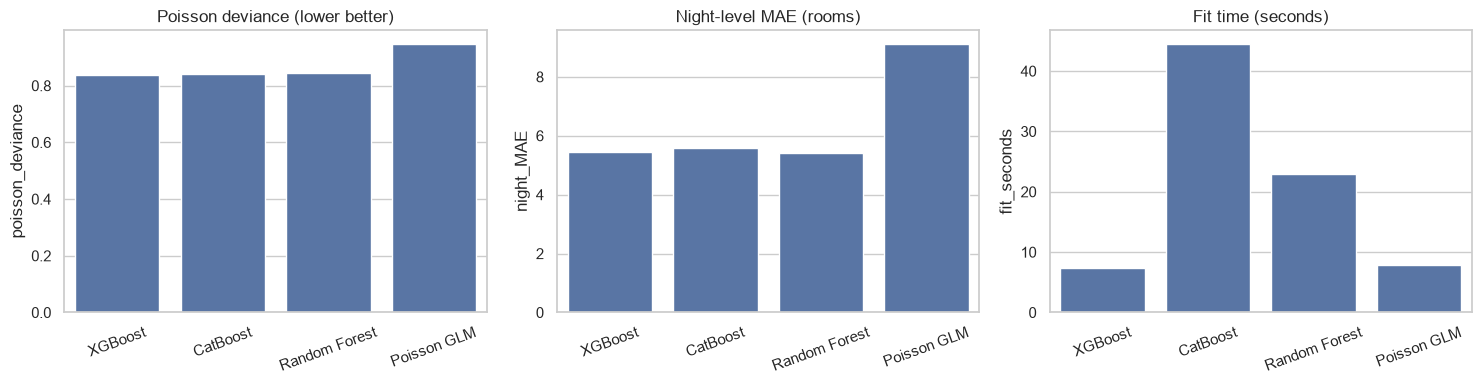

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order = comparison.sort_values("poisson_deviance")["model"]

for ax, metric, title in zip(
        axes,
        ["poisson_deviance", "night_MAE", "fit_seconds"],
        ["Poisson deviance (lower better)", "Night-level MAE (rooms)",
         "Fit time (seconds)"]):
    sns.barplot(data=comparison, x="model", y=metric, order=order, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
fig.savefig(REPORTS / "08_model_comparison.png", bbox_inches="tight")
plt.show()

In [5]:
best_name = comparison.sort_values("poisson_deviance").iloc[0]["model"]
best = fitted[best_name]
print(f"Selected: {best_name}")

X_test, y_test, test_frame = splits["test"]
pred = np.clip(best.predict(X_test), 0, None)

Selected: XGBoost


## 4. Where does the accuracy come from?

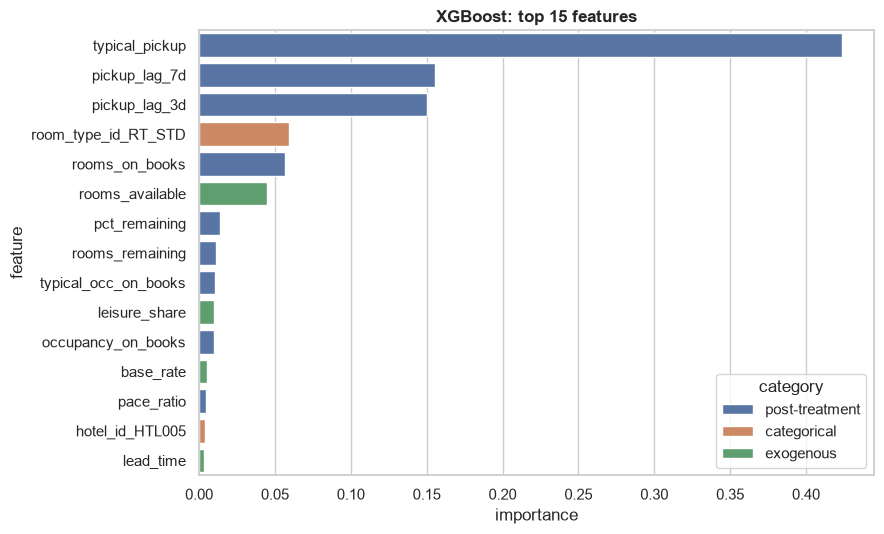

Total importance by category:
post-treatment    0.844
exogenous         0.077
categorical       0.072
price             0.007


In [6]:
importance = (pd.Series(best.feature_importances_, index=feature_cols)
              .sort_values(ascending=False))


def category(feature: str) -> str:
    if feature in F.FEATURES_POST_TREATMENT:
        return "post-treatment"
    if feature in F.FEATURES_PRICE:
        return "price"
    if feature in F.FEATURES_EXOGENOUS:
        return "exogenous"
    return "categorical"


top = importance.head(15).reset_index()
top.columns = ["feature", "importance"]
top["category"] = top["feature"].map(category)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=top, y="feature", x="importance", hue="category",
            dodge=False, ax=ax)
ax.set_title(f"{best_name}: top 15 features", fontweight="bold")
plt.tight_layout()
fig.savefig(REPORTS / "09_feature_importance.png", bbox_inches="tight")
plt.show()

by_cat = importance.groupby(importance.index.map(category)).sum()
print("Total importance by category:")
print((by_cat / by_cat.sum()).sort_values(ascending=False).round(3).to_string())

### The post-treatment features dominate — and price barely registers

`typical_pickup` and `pickup_lag_7d` alone account for over half the model's
importance. `rooms_on_books` adds more. The price features contribute almost nothing.

Both halves of that are worth sitting with.

**Pace features are where forecasting accuracy lives.** Knowing what this night
normally does at this lead time, plus what it did yesterday, is most of the problem.
This is exactly the payoff Phase 4 predicted, and exactly why excluding them from
the causal model cost us something real.

**Price barely matters to the forecast.** Which should be surprising — Phase 5b
proved demand is strongly price-sensitive (−1.5). The resolution is that in the
training data, price moves *with* demand, so once the model knows pace and season,
price adds little incremental information. It has not learned that price is
unimportant; it has learned that price is redundant given everything else.

That distinction is the whole reason the next section matters.

## 5. What the post-treatment features are worth

Phase 4 excluded them from the causal model. Here is the accuracy that cost.

In [7]:
from xgboost import XGBRegressor

data = df.copy()
for col in data.columns:
    if data[col].dtype == bool:
        data[col] = data[col].astype(int)
dummies = pd.get_dummies(data[F.CATEGORICALS], drop_first=True).astype(int)

ablation = []
for label, feats in [("Predictive set (36 features)", F.FEATURES_PREDICTIVE),
                     ("Causal set only (21 features)", F.FEATURES_CAUSAL)]:
    X = pd.concat([data[feats], dummies], axis=1).astype(float)
    tr = (data["split"] == "train").to_numpy()
    va = (data["split"] == "val").to_numpy()
    te = (data["split"] == "test").to_numpy()

    model = XGBRegressor(objective="count:poisson", n_estimators=600,
                         learning_rate=0.05, max_depth=7, subsample=0.8,
                         colsample_bytree=0.8, min_child_weight=5,
                         n_jobs=-1, random_state=42,
                         early_stopping_rounds=40,
                         eval_metric="poisson-nloglik")
    model.fit(X[tr], data[D.TARGET][tr],
              eval_set=[(X[va], data[D.TARGET][va])], verbose=False)
    p = np.clip(model.predict(X[te]), 0, None)

    row = {"feature set": label}
    row.update({k: round(v, 4) for k, v in D.cell_metrics(data[D.TARGET][te], p).items()})
    row.update({k: round(v, 3) for k, v in D.night_metrics(data[te], p).items()})
    ablation.append(row)

pd.DataFrame(ablation)[["feature set", "MAE", "poisson_deviance", "night_MAE"]]

,feature set,MAE,poisson_deviance,night_MAE
0,Predictive set (36 features),0.6102,0.8379,5.436
1,Causal set only (21 features),0.6279,0.8749,5.905


Dropping the post-treatment features costs about **4% of deviance** and half a room
of night-level accuracy. Real, but modest.

Which makes the trade-off explicit: **for forecasting we pay ~4% accuracy to keep
those features; for causal estimation, including them tripled the elasticity error.**
Same columns, opposite verdicts, because the questions differ.

## 6. Error analysis

Aggregate metrics hide where a model actually fails. Two cuts matter operationally.

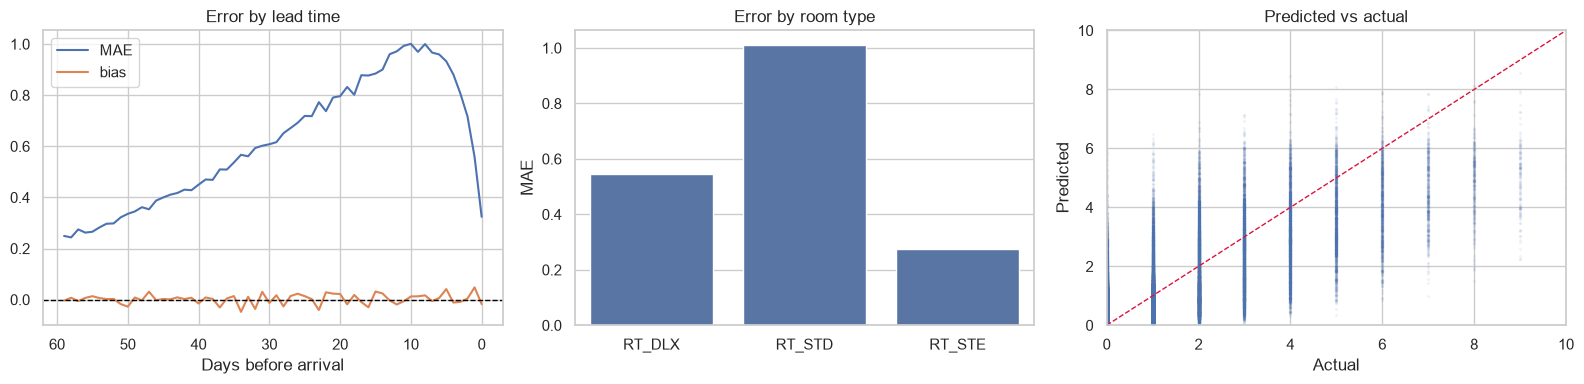

In [8]:
resid = test_frame[["hotel_id", "room_type_id", "segment", "lead_time",
                    "stay_date", D.TARGET, "rooms_available"]].copy()
resid["pred"] = pred
resid["error"] = resid["pred"] - resid[D.TARGET]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

by_lead = resid.groupby("lead_time").agg(
    MAE=("error", lambda s: s.abs().mean()),
    bias=("error", "mean")).reset_index()
axes[0].plot(by_lead["lead_time"], by_lead["MAE"], label="MAE")
axes[0].plot(by_lead["lead_time"], by_lead["bias"], label="bias")
axes[0].axhline(0, color="black", lw=1, ls="--")
axes[0].invert_xaxis()
axes[0].set_xlabel("Days before arrival")
axes[0].set_title("Error by lead time")
axes[0].legend()

by_rt = resid.groupby("room_type_id").agg(
    MAE=("error", lambda s: s.abs().mean())).reset_index()
sns.barplot(data=by_rt, x="room_type_id", y="MAE", ax=axes[1])
axes[1].set_title("Error by room type")
axes[1].set_xlabel("")

axes[2].scatter(resid[D.TARGET], resid["pred"], s=2, alpha=0.05)
lim = [0, resid[D.TARGET].quantile(0.999)]
axes[2].plot(lim, lim, ls="--", color="crimson", lw=1)
axes[2].set_xlim(lim)
axes[2].set_ylim(lim)
axes[2].set_xlabel("Actual")
axes[2].set_ylabel("Predicted")
axes[2].set_title("Predicted vs actual")

plt.tight_layout()
fig.savefig(REPORTS / "10_error_analysis.png", bbox_inches="tight")
plt.show()

Error is largest close to arrival, where daily pickup is highest and most volatile —
and that is precisely when pricing decisions are most urgent. Worth stating plainly
as a limitation rather than burying it.

## 7. The finding that justifies two models

Now we ask the demand model a pricing question. Take real test rows, sweep the rate
while holding everything else fixed, and record predicted demand. This is a partial
dependence plot on the treatment variable.

If the model understood price, this curve's slope would match the causal elasticity
from Phase 5b.

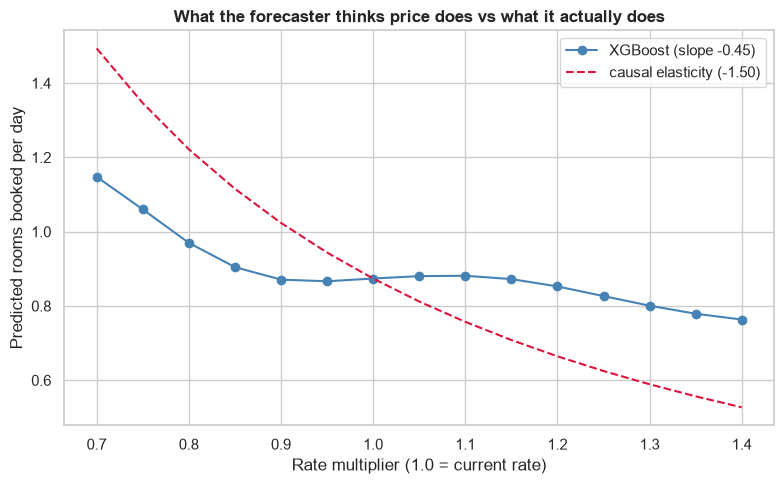

Implied elasticity from XGBoost       : -0.451
Causal elasticity from Phase 5b        : -1.503
Understated by                         : 3.3x


In [9]:
curve = D.price_response_curve(best, splits)
elasticities = pd.read_csv(MODELS / "elasticities.csv")
causal = elasticities["elasticity"].mean()
implied = curve.attrs["implied_elasticity"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(curve["rate_multiplier"], curve["predicted_demand"],
        "o-", color="steelblue", label=f"{best_name} (slope {implied:+.2f})")

# What the causal elasticity implies, anchored at the current rate
anchor = curve.loc[curve["rate_multiplier"].sub(1.0).abs().idxmin(),
                   "predicted_demand"]
ax.plot(curve["rate_multiplier"],
        anchor * curve["rate_multiplier"] ** causal,
        "--", color="crimson", label=f"causal elasticity ({causal:+.2f})")

ax.set_xlabel("Rate multiplier (1.0 = current rate)")
ax.set_ylabel("Predicted rooms booked per day")
ax.set_title("What the forecaster thinks price does vs what it actually does",
             fontweight="bold")
ax.legend()
plt.tight_layout()
fig.savefig(REPORTS / "11_price_response_gap.png", bbox_inches="tight")
plt.show()

print(f"Implied elasticity from {best_name:<14}: {implied:+.3f}")
print(f"Causal elasticity from Phase 5b        : {causal:+.3f}")
print(f"Understated by                         : {abs(causal / implied):.1f}x")

### The best forecaster thinks demand is 3× less price-sensitive than it is

XGBoost is the most accurate model we have. Its implied elasticity is about **−0.50**.
The true value is **−1.50**.

**The model is not broken.** It was never told that price *causes* demand. It learned
that in the training data high rates accompany high demand — because the legacy rule
set them that way — and that correlation partly offsets the true negative effect.
Section 4 showed why it barely leans on price at all: given pace and season, price is
redundant.

**But used for pricing it would be dangerous.** Feed it to the optimizer and it
recommends raising rates almost everywhere, predicting a volume loss three times
smaller than reality. Every recommendation would be biased toward overpricing, and
the forecast would confirm the decision was fine.

> A model can be the most accurate forecaster available and the wrong tool for
> setting prices. Accuracy on the observed distribution says nothing about behaviour
> under an intervention you have never made.

This is why Phase 6 uses **both**: the demand model for the baseline forecast, the
causal elasticity for how that baseline responds to a price change.

## 8. Export

In [10]:
import pickle

with open(MODELS / "demand_model.pkl", "wb") as fh:
    pickle.dump({"model": best, "name": best_name, "features": feature_cols}, fh)

comparison.to_csv(REPORTS / "model_comparison.csv", index=False)
curve.to_csv(REPORTS / "demand_model_price_response.csv", index=False)
importance.head(25).to_csv(REPORTS / "feature_importance.csv")

print("Exported:")
print(f"  models/demand_model.pkl                  -> Phase 6 ({best_name})")
print("  reports/model_comparison.csv")
print("  reports/demand_model_price_response.csv")
print("  reports/feature_importance.csv")

Exported:
  models/demand_model.pkl                  -> Phase 6 (XGBoost)
  reports/model_comparison.csv
  reports/demand_model_price_response.csv
  reports/feature_importance.csv


## What Phase 6 does with this

The optimizer needs two things, and they come from different places:

```
expected_bookings(rate) = demand_model_forecast × (rate / current_rate) ^ elasticity
                          └── Phase 5a ──┘         └──── Phase 5b ────┘
expected_revenue(rate)  = expected_bookings(rate) × rate
```

The demand model supplies the **level** — how many rooms this night would sell at the
current rate. The causal elasticity supplies the **response** — how that level moves
when we change the rate. Neither model can do both jobs.

Then the constraints that make it a hotel problem rather than a calculus exercise:

- Never price below cost plus minimum margin
- Cap rate changes at ±15% to avoid whiplash
- **Respect remaining capacity** — every estimate is below −1, so revenue-maximising
  price cuts are tempting, but discounting a night already at 95% occupancy sells a
  few extra rooms and marks down all the rest
- Carry the elasticity confidence intervals through, so segments we know little about
  (HTL001 suites: −1.14 to −0.39) get more conservative recommendations